## Ques 2

In [1]:
path = 'heart_failure_clinical_records_dataset.csv'

In [2]:
import pandas as pd
import numpy as np

In [3]:
df = pd.read_csv(path)
df['smoking'] = df['smoking'].astype(object)

old_df = df.copy()

In [4]:
df.head(5)

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,-75.0,0.0,582.0,0.0,20,1.0,265000.00,1.9,130.0,1.0,0,4.0,1.0
1,55.0,0.0,7861.0,0.0,38,0.0,263358.03,1.1,136.0,1.0,0,6.0,1.0
2,65.0,0.0,146.0,0.0,20,0.0,162000.00,1.3,129.0,1.0,1,7.0,1.0
3,NaN,1.0,111.0,0.0,20,0.0,210000.00,1.9,137.0,1.0,0,7.0,1.0
4,65.0,1.0,160.0,1.0,20,0.0,327000.00,2.7,116.0,0.0,0,8.0,1.0


## Ques 3

In [5]:
df.describe()

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,time,DEATH_EVENT
count,298.000000,298.000000,296.000000,296.000000,299.000000,296.000000,297.000000,298.000000,298.000000,298.000000,295.000000,298.000000
mean,60.366893,0.432886,585.304054,0.418919,38.083612,0.347973,263094.446970,1.395201,136.640940,0.647651,130.572881,0.322148
std,14.240689,0.496309,974.287833,0.494218,11.834841,0.477134,97785.824384,1.035997,4.411716,0.478506,77.463974,0.468085
min,-75.000000,0.000000,23.000000,0.000000,14.000000,0.000000,25100.000000,0.500000,113.000000,0.000000,4.000000,0.000000
25%,51.000000,0.000000,118.750000,0.000000,30.000000,0.000000,213000.000000,0.900000,134.000000,0.000000,73.500000,0.000000
50%,60.000000,0.000000,250.000000,0.000000,38.000000,0.000000,262000.000000,1.100000,137.000000,1.000000,115.000000,0.000000
75%,70.000000,1.000000,582.000000,1.000000,45.000000,1.000000,303000.000000,1.400000,140.000000,1.000000,203.000000,1.000000
max,95.000000,1.000000,7861.000000,1.000000,80.000000,1.000000,850000.000000,9.400000,148.000000,1.000000,285.000000,1.000000


In [6]:
print("Rows:", df.shape[0])
print("Cols:", df.shape[1])

Rows: 299
Cols: 13


In [7]:
df.dtypes

age                         float64
anaemia                     float64
creatinine_phosphokinase    float64
diabetes                    float64
ejection_fraction             int64
high_blood_pressure         float64
platelets                   float64
serum_creatinine            float64
serum_sodium                float64
sex                         float64
smoking                      object
time                        float64
DEATH_EVENT                 float64
dtype: object

In [8]:
df.isnull().sum()

age                         1
anaemia                     1
creatinine_phosphokinase    3
diabetes                    3
ejection_fraction           0
high_blood_pressure         3
platelets                   2
serum_creatinine            1
serum_sodium                1
sex                         1
smoking                     0
time                        4
DEATH_EVENT                 1
dtype: int64

## Ques 4

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

<Axes: >

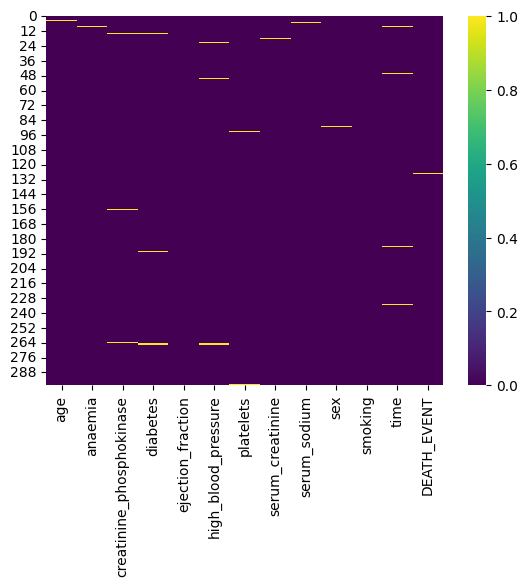

In [10]:
sns.heatmap(df.isnull(),
           cmap="viridis")


## Ques 5

In [11]:
df.select_dtypes(include='int').columns

Index(['ejection_fraction'], dtype='object')

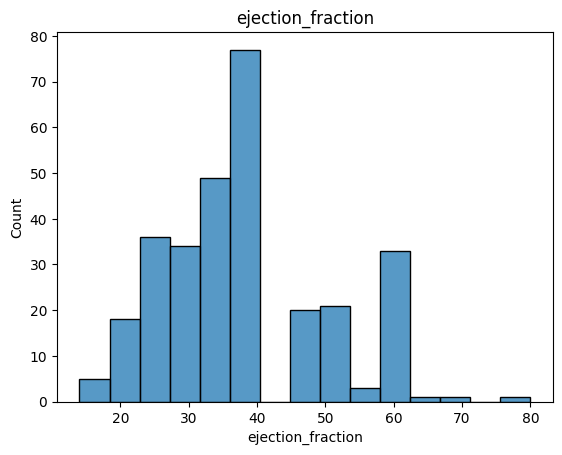

In [12]:
for col in df.select_dtypes(include="int").columns:
    if df[col].nunique() > 2:        
        sns.histplot(data=df, x=col)
        plt.title(col)
        plt.show()

## Ques 6

In [13]:
float_col = df.select_dtypes(float).columns[
    df.select_dtypes(float).nunique() <= 2
]
df[float_col] = df[float_col].astype('Int64')

In [15]:
col = df.select_dtypes(include = [int, float]).columns.tolist()
for c in col:
    if df[c].nunique() <=2 :
        df[c] = df[c].fillna(df[c].median())
    else :
        # df[c] = df[c].fillna(df[c].median())
        df[c] = df[c].fillna(df[c].mean())

In [16]:
col = df.select_dtypes(exclude = [int, float]).columns.tolist()
df[col] = df[col].fillna(df[col].mode().iloc[0])


C:\Users\hpCND\AppData\Local\Temp\ipykernel_21688\1409023522.py:2: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[col] = df[col].fillna(df[col].mode().iloc[0])


## Ques 7 

In [17]:
num_cols = df.select_dtypes([int, float]).columns.tolist()

In [18]:
for c in num_cols:
    Q1 = df[c].quantile(0.25)
    Q3 = df[c].quantile(0.75)
    
    IQR = Q3 - Q1
    
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df = df[(df[c] > lower) & (df[c] < upper)]

## Ques 8

In [19]:
for c in num_cols:
    if (df[c] < 0).any():
        print(c)
        
print("---")

---


In [20]:
lst = []

for c in num_cols:
    if (df[c] % 1 != 0).any():
        print(c, "--------------" , (df[c] % 1 != 0).sum()) 

age -------------- 3
creatinine_phosphokinase -------------- 3
platelets -------------- 21
serum_creatinine -------------- 183
serum_sodium -------------- 1
time -------------- 3


In [21]:
for c in num_cols:
    if (df[c]%1 != 0).sum() < 5:
        df[c] = df[c].round().astype('Int64')

In [22]:
lst = []

for c in num_cols:
    if (df[c] % 1 != 0).any():
        print(c, "--------------" , (df[c] % 1 != 0).sum()) 

platelets -------------- 21
serum_creatinine -------------- 183


## Ques 9

In [23]:
df['new_age'] = pd.cut(
    df['age'],
    bins=[-float('inf'), 40, 60, float('inf')],
    labels=['<40', '40-60', '>60'],
    right=False,
)
df.drop('age', axis=1, inplace=True)

In [24]:
from sklearn.preprocessing import MinMaxScaler
new_df = df[['ejection_fraction', 'serum_creatinine']]
sc = MinMaxScaler()
new_df = pd.DataFrame(sc.fit_transform(new_df), index=new_df.index, columns=new_df.columns)

In [25]:
new_df.head(5)

,ejection_fraction,serum_creatinine
2,0.117647,0.466667
3,0.117647,0.866667
5,0.509804,1.000000
6,0.019608,0.400000
8,1.000000,0.600000


In [26]:
df['risk_score'] = new_df['ejection_fraction'] * new_df['serum_creatinine']

In [27]:
df.head(5)

,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT,new_age,risk_score
2,0,146,0,20,0,162000.00,1.3,129,1,1,7,1,>60,0.054902
3,1,111,0,20,0,210000.00,1.9,137,1,0,7,1,>60,0.101961
5,1,47,0,40,1,204000.00,2.1,137,1,1,8,1,>60,0.509804
6,1,246,0,15,0,127000.00,1.2,137,1,0,10,1,>60,0.007843
8,0,157,0,65,0,263358.03,1.5,138,0,0,131,1,>60,0.600000


In [28]:
# df['age_group'] = np.select(
#     [
#         df['age'] < 40,
#         (df['age'] >= 40) & (df['age'] <= 60),
#         df['age'] > 60
#     ],
#     [
#         '<40',
#         '40-60',
#         '>60'
#     ]
# )

In [29]:
# df['age_group'] = np.where(
#     df['age'] < 40,
#     '<40',
#     np.where(
#         (df['age'] >= 40) & (df['age'] <= 60),
#         '40-60',
#         '>60'
#     )
# )

## Ques 10

In [30]:
df = pd.get_dummies(
    df,
    columns=['sex', 'smoking', 'new_age'],
    drop_first=True,
    dtype=int
)

## Ques 11

In [31]:
col = [
    c for c in df.select_dtypes([int, float]).columns
    if df[c].nunique() > 3
]

In [32]:
from sklearn.preprocessing import MinMaxScaler
sc = MinMaxScaler()
df[col] = pd.DataFrame(sc.fit_transform(df[col]), index=df.index, columns = col)

## Ques 12

In [33]:
before = old_df.select_dtypes([int, float]).agg(
    ['mean', 'median', 'std']
)

after = df.select_dtypes([int, float]).agg(
    ['mean', 'median', 'std']
)

print("Before cleaning:")
print(before)
print("===============================================================================")
print("\nAfter cleaning:")
print(after)

Before cleaning:
              age   anaemia  creatinine_phosphokinase  diabetes  \
mean    60.366893  0.432886                585.304054  0.418919   
median  60.000000  0.000000                250.000000  0.000000   
std     14.240689  0.496309                974.287833  0.494218   

        ejection_fraction  high_blood_pressure      platelets  \
mean            38.083612             0.347973  263094.446970   
median          38.000000             0.000000  262000.000000   
std             11.834841             0.477134   97785.824384   

        serum_creatinine  serum_sodium       sex        time  DEATH_EVENT  
mean            1.395201    136.640940  0.647651  130.572881     0.322148  
median          1.100000    137.000000  1.000000  115.000000     0.000000  
std             1.035997      4.411716  0.478506   77.463974     0.468085  

After cleaning:
         anaemia  creatinine_phosphokinase  diabetes  ejection_fraction  \
mean    0.472973                  0.263633  0.414414     

## Ques 13

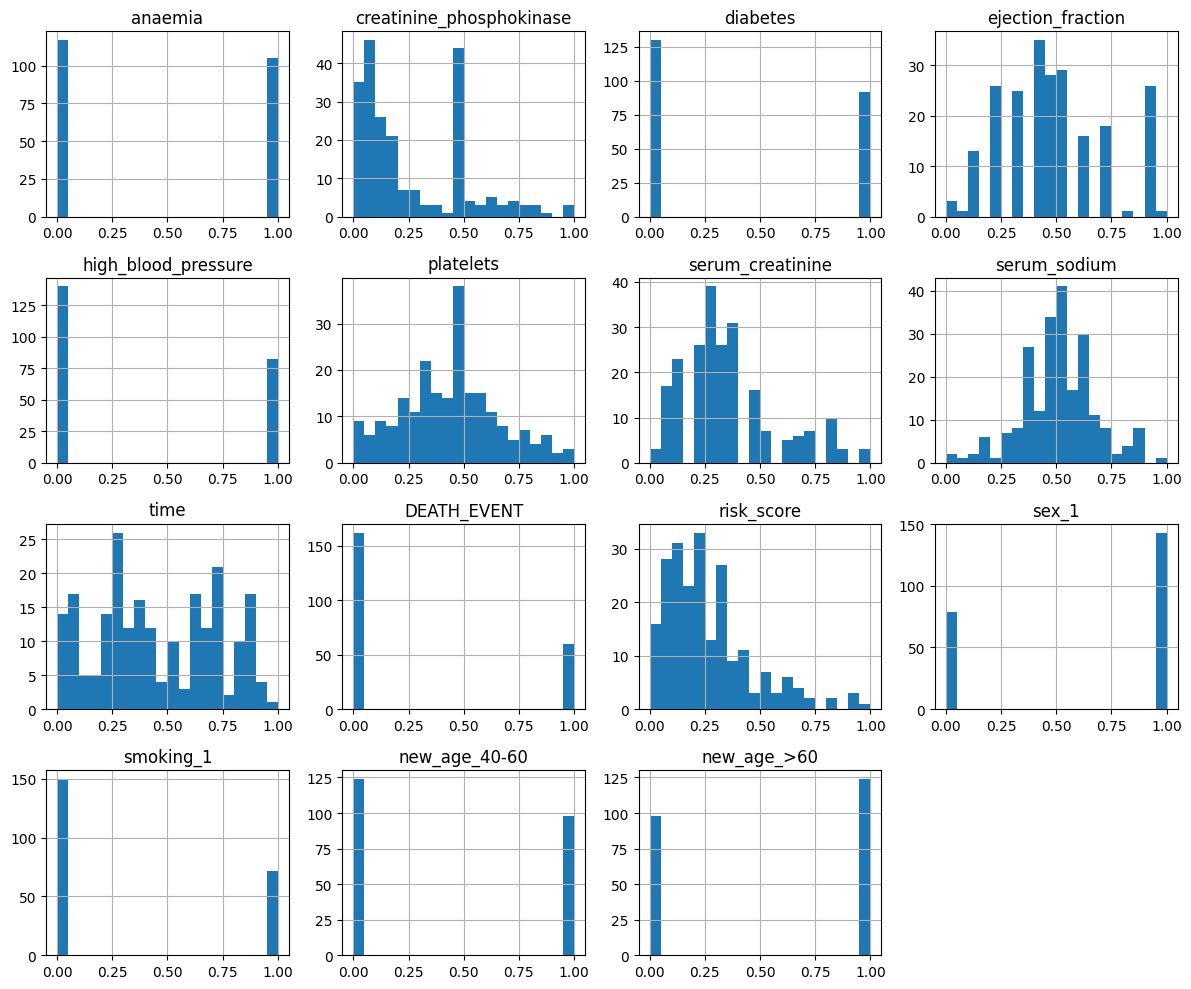

In [34]:
col = df.columns
df[col].hist(figsize=(12, 10), bins=20)

plt.tight_layout()
plt.show()

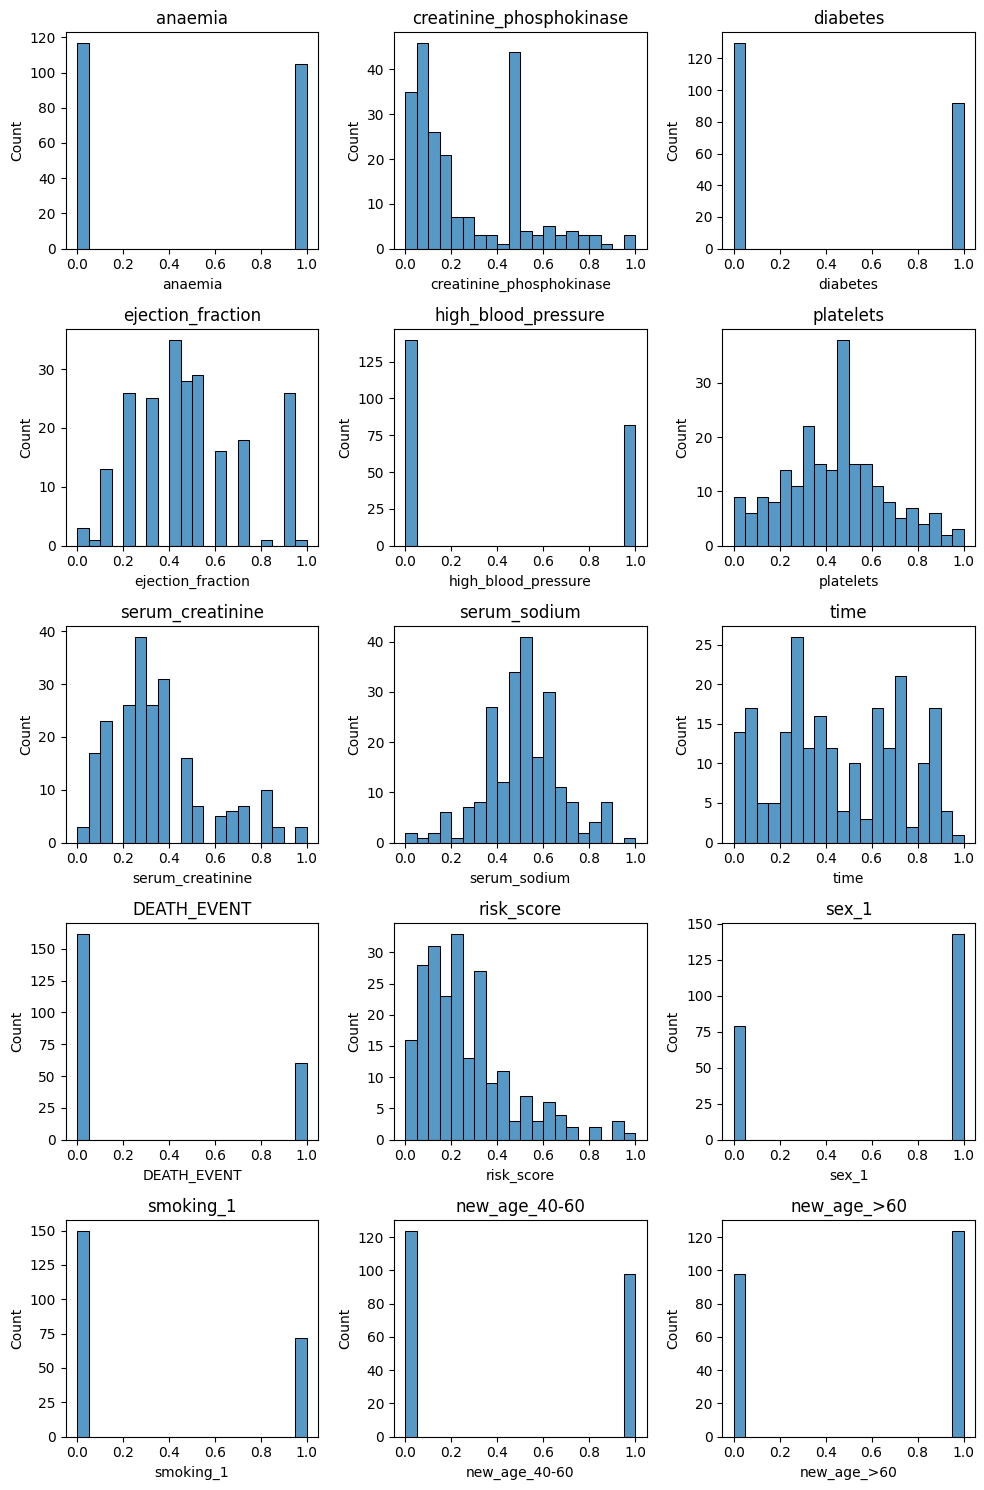

In [35]:
fig, axes = plt.subplots(
    5, 3,
    figsize=(10, 15)
)

axes = axes.flatten()

for i, c in enumerate(col):
    sns.histplot(df[c], bins=20, ax=axes[i])
    axes[i].set_title(c)

plt.tight_layout()
plt.show()

## Ques 14

In [36]:
df.isnull().sum()

anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creatinine            0
serum_sodium                0
time                        0
DEATH_EVENT                 0
risk_score                  0
sex_1                       0
smoking_1                   0
new_age_40-60               0
new_age_>60                 0
dtype: int64

In [37]:
df.head(10)

,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,time,DEATH_EVENT,risk_score,sex_1,smoking_1,new_age_40-60,new_age_>60
2,0,0.098976,0,0.117647,0,0.131148,0.466667,0.136364,0.000000,1,0.091503,1,1,0,1
3,1,0.069113,0,0.117647,0,0.288525,0.866667,0.500000,0.000000,1,0.169935,1,0,0,1
5,1,0.014505,0,0.509804,1,0.268852,1.000000,0.500000,0.003597,1,0.849673,1,1,0,1
6,1,0.184300,0,0.019608,0,0.016393,0.400000,0.500000,0.010791,1,0.013072,1,0,0,1
8,0,0.108362,0,1.000000,0,0.463469,0.600000,0.545455,0.446043,1,1.000000,0,0,0,1
11,0,0.171502,0,0.215686,1,0.429508,0.200000,0.636364,0.010791,1,0.071895,1,1,0,1
12,1,0.811433,0,0.313725,0,0.045902,0.333333,0.500000,0.014388,1,0.174292,1,0,1,0
13,1,0.117747,0,0.470588,1,0.504918,0.333333,0.500000,0.014388,1,0.261438,1,0,1,0
14,1,0.473549,0,0.313725,1,1.000000,0.266667,0.545455,0.017986,0,0.139434,0,0,1,0
16,1,0.101536,0,0.470588,0,0.459016,0.200000,0.636364,0.025180,1,0.156863,1,0,0,1
